In [1]:
!pip -q install -U ultralytics pyyaml

import torch, ultralytics
ultralytics.checks()
print("CUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)
CUDA: True | Tesla T4


In [2]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="VT4QKmGnmUFK8WcGIVhV")
project = rf.workspace("loiss-workspace").project("tennis-ball-g2y4w")
version = project.version(1)
dataset = version.download("yolo26")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.5 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to tennis-ball-1 in yolo26:: 100%|██████████| 502/502 [00:00<00:00, 5607.22it/s]


In [3]:
import cv2
from pathlib import Path

# Tìm và kiểm tra kích thước của một vài ảnh trong tập train
data_path = Path("/content/tennis-ball-1")
if not data_path.exists():
    # Thử tìm các file ảnh bất kỳ trong thư mục vừa tải
    data_path = Path("./yolo26")

image_files = list(data_path.rglob("*.jpg")) + list(data_path.rglob("*.png")) + list(data_path.rglob("*.jpeg"))

if image_files:
    print(f"Tìm thấy {len(image_files)} ảnh. Dưới đây là kích thước của 5 ảnh đầu tiên:")
    for img_path in image_files[:5]:
        img = cv2.imread(str(img_path))
        if img is not None:
            h, w, c = img.shape
            print(f"- {img_path.name}: {w}x{h} (rộng x cao), {c} channels")
else:
    print("Không tìm thấy ảnh nào trong thư mục dataset để kiểm tra size.")

Tìm thấy 249 ảnh. Dưới đây là kích thước của 5 ảnh đầu tiên:
- frame_000189_jpg.rf.a00bb5af0df1d3f329b462262ac69b32.jpg: 1920x1080 (rộng x cao), 3 channels
- frame_000372_jpg.rf.3f48c231e29f61f23a2c9b140026c2a6.jpg: 1920x1080 (rộng x cao), 3 channels
- frame_000630_jpg.rf.fef61a208dec5208e39ce9f95b83f001.jpg: 1920x1080 (rộng x cao), 3 channels
- frame_000102_jpg.rf.1eed81df0b6b383ddd52bc582d133cc5.jpg: 1920x1080 (rộng x cao), 3 channels
- frame_000279_jpg.rf.cbf4b312afa3fdbe418451302cce6e31.jpg: 1920x1080 (rộng x cao), 3 channels


## 1. Cấu hình

In [4]:
from pathlib import Path

# ===== CẤU HÌNH =====
DATA_DIR  = Path("/content/tennis-ball-1")     # thư mục chứa dataset (đã giải nén)
DATA_YAML = DATA_DIR / "data.yaml"

MODEL          = "yolo26m.pt"   # đổi thành yolo26n.pt / yolo26m.pt ... nếu muốn
FALLBACK_MODEL = "yolo11m.pt"   # dùng khi bản ultralytics chưa hỗ trợ YOLO26

IMGSZ  = 1280    # 960 train nhanh hơn ~1.7 lần (nên thử trước); 1280 nếu bóng rất nhỏ
EPOCHS = 120
BATCH  = 16      # giảm còn 8 hoặc 4 nếu bị CUDA out of memory (imgsz=1280)

PROJECT  = "runs_tennis"
RUN_NAME = "ball_train"

## 2. Chuẩn bị dataset

Chọn **một** cách (bỏ comment dòng tương ứng). Sau đó ô tiếp theo sẽ tự sửa đường dẫn trong `data.yaml` cho đúng.

In [ ]:
print("data.yaml tồn tại:", DATA_YAML.exists())

data.yaml tồn tại: True


In [6]:
import yaml


def find_split_dir(data_dir, names):
    """Tìm thư mục ảnh của 1 split, hỗ trợ cả 'train/images' lẫn 'images/train'."""
    for n in names:
        for sub in (f"{n}/images", f"images/{n}"):
            if (data_dir / sub).exists():
                return sub
    return None


cfg = yaml.safe_load(open(DATA_YAML))
cfg["path"] = str(DATA_DIR.resolve())

for split, aliases in {"train": ["train"], "val": ["valid", "val", "validation"], "test": ["test"]}.items():
    found = find_split_dir(DATA_DIR, aliases)
    if found:
        cfg[split] = found
    elif split != "test":
        print(f"⚠️ Không tìm thấy thư mục cho split '{split}', giữ nguyên giá trị trong yaml: {cfg.get(split)}")
    else:
        cfg.pop("test", None)

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

print(open(DATA_YAML).read())

train: train/images
val: valid/images
nc: 1
names:
- tennis-ball
roboflow:
  workspace: loiss-workspace
  project: tennis-ball-g2y4w
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/loiss-workspace/tennis-ball-g2y4w/dataset/1
path: /content/tennis-ball-1



## 3. Kiểm tra dataset

Với vật thể nhỏ, điều quan trọng nhất là biết **bóng chiếm bao nhiêu pixel** sau khi resize về `IMGSZ`. Ô này thống kê kích thước box và vẽ vài ảnh mẫu.

train:   199 ảnh |    199 box | 0 ảnh nền (không có box)
val  :    50 ảnh |     50 box | 0 ảnh nền (không có box)

Kích thước bóng ở imgsz=1280 (pixel):
  P05: 4.8px
  P25: 6.5px
  P50: 9.4px
  P75: 15.2px
  P95: 21.4px
  Tỉ lệ box < 16px: 75.4% | < 32px: 100.0%


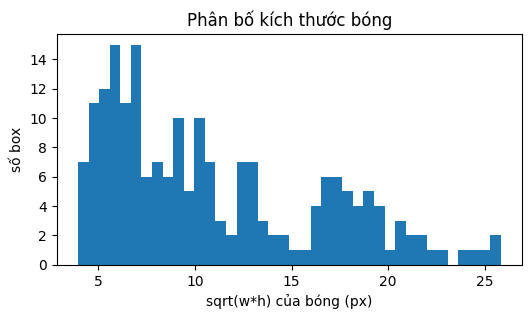

In [7]:
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def list_images(split):
    d = DATA_DIR / cfg[split]
    return sorted(p for p in d.rglob("*") if p.suffix.lower() in IMG_EXT)


def label_path(img_path):
    parts = list(img_path.parts)
    i = len(parts) - 1 - parts[::-1].index("images")
    parts[i] = "labels"
    return Path(*parts).with_suffix(".txt")


def read_labels(img_path):
    lp = label_path(img_path)
    if not lp.exists():
        return np.zeros((0, 5))

    valid_rows = []
    for line in lp.read_text().splitlines():
        parts = line.strip().split()
        if len(parts) == 5:
            try:
                valid_rows.append([float(x) for x in parts])
            except ValueError:
                continue

    return np.array(valid_rows, dtype=float).reshape(-1, 5) if valid_rows else np.zeros((0, 5))


for s in ("train", "val", "test"):
    if s in cfg:
        imgs = list_images(s)
        n_obj = sum(len(read_labels(p)) for p in imgs)
        n_bg = sum(len(read_labels(p)) == 0 for p in imgs)
        print(f"{s:5s}: {len(imgs):5d} ảnh | {n_obj:6d} box | {n_bg} ảnh nền (không có box)")

# Thống kê kích thước box (pixel quy đổi theo cạnh dài của ảnh = IMGSZ)
train_imgs = list_images("train")
sizes = []
for p in train_imgs:
    lab = read_labels(p)
    if len(lab):
        h_img, w_img = cv2.imread(str(p)).shape[:2]
        scale = IMGSZ / max(h_img, w_img)
        sizes += [(w * w_img * scale, h * h_img * scale) for _, _, _, w, h in lab]
sizes = np.array(sizes)

if len(sizes):
    side = np.sqrt(sizes[:, 0] * sizes[:, 1])
    print(f"\nKích thước bóng ở imgsz={IMGSZ} (pixel):")
    for q in (5, 25, 50, 75, 95):
        print(f"  P{q:02d}: {np.percentile(side, q):.1f}px")
    print(f"  Tỉ lệ box < 16px: {(side < 16).mean():.1%} | < 32px: {(side < 32).mean():.1%}")
    plt.figure(figsize=(6, 3))
    plt.hist(side, bins=40)
    plt.xlabel("sqrt(w*h) của bóng (px)")
    plt.ylabel("số box")
    plt.title("Phân bố kích thước bóng")
    plt.show()

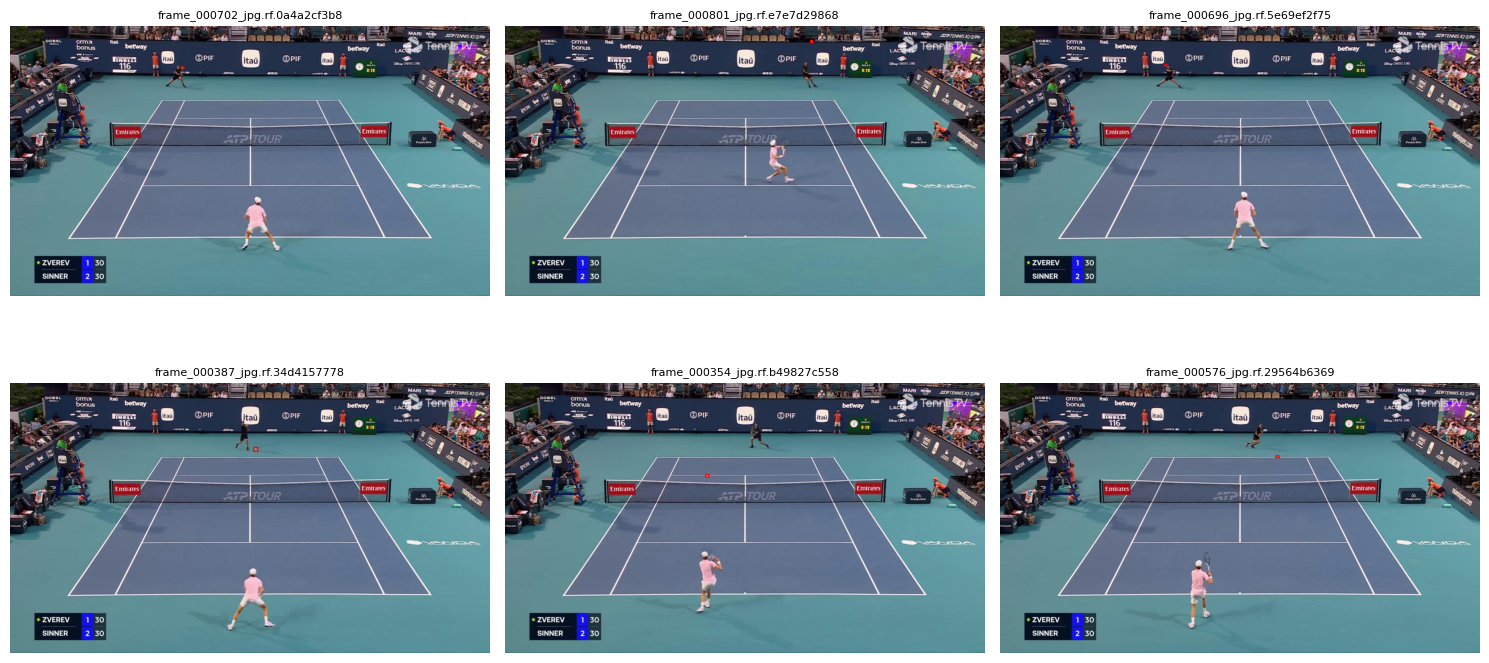

In [8]:
def show_samples(img_paths, n=6, cols=3):
    sel = random.sample(img_paths, min(n, len(img_paths)))
    rows = (len(sel) + cols - 1) // cols
    plt.figure(figsize=(5 * cols, 4 * rows))
    for i, p in enumerate(sel):
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = im.shape[:2]
        for _, cx, cy, bw, bh in read_labels(p):
            x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
            x2, y2 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)
            cv2.rectangle(im, (x1, y1), (x2, y2), (255, 0, 0), max(2, w // 400))
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im)
        plt.axis("off")
        plt.title(p.name[:30], fontsize=8)
    plt.tight_layout()
    plt.show()


show_samples(train_imgs)

## 4. Huấn luyện

Giải thích các hyperparameter chính (phần còn lại để mặc định của Ultralytics):

| Tham số | Giá trị | Ghi chú |
|---|---|---|
| `imgsz` | 1280 | Quan trọng nhất cho vật thể nhỏ. Nên infer cùng `imgsz` với lúc train. |
| `epochs` / `patience` | 120 / 30 | Dataset nhỏ (vài trăm–vài nghìn ảnh) cần ~100+ epoch; early stopping nếu mAP không cải thiện. |
| `optimizer` | `auto` | Ultralytics tự chọn (AdamW cho lần train ngắn, MuSGD/SGD cho lần train dài). Tinh chỉnh bằng `lr0` nếu loss không ổn định. |
| `cos_lr` | True | Learning rate giảm theo cosine, ổn định ở cuối quá trình train. |
| `close_mosaic` | 15 | Tắt mosaic ở 15 epoch cuối để model học trên ảnh "thật". |
| `mosaic` | 1.0 | Giữ lại – giúp tăng đa dạng bối cảnh. |
| `scale` | 0.3 | Mặc định là 0.5; giảm để bóng không bị thu nhỏ quá mức. |
| `degrees`, `shear`, `perspective`, `flipud` | 0 | Bóng tròn nên không cần; sân tennis có hướng cố định nên không lật dọc. |
| `fliplr` | 0.5 | Lật ngang an toàn. |
| `hsv_h/s/v` | 0.015 / 0.7 / 0.4 | Mặc định, giúp bền với ánh sáng khác nhau. |
| `mixup`, `copy_paste` | 0 | Dễ làm hỏng vật thể rất nhỏ. |

In [9]:

from pathlib import Path
from ultralytics import YOLO

model_path = MODEL

try:
    model = YOLO(model_path)
except Exception as e:
    if not FALLBACK_MODEL:
        raise RuntimeError(
            f"Không tải được model {model_path}"
        ) from e

    print(
        f"Không tải được {model_path}: {e}\n"
        f"Chuyển sang {FALLBACK_MODEL}"
    )
    model_path = FALLBACK_MODEL
    model = YOLO(model_path)

results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=10,

    # Optimizer and learning-rate schedule
    optimizer="auto",
    cos_lr=True,
    warmup_epochs=3,

    # Augmentation
    mosaic=1.0,
    close_mosaic=15,
    scale=0.3,
    translate=0.1,
    degrees=0.0,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    mixup=0.0,
    copy_paste=0.0,

    # Reproducibility and performance
    project=PROJECT,
    name=RUN_NAME,
    exist_ok=True,
    workers=2,
    seed=0,
    amp=True,
    plots=True,
)

print(f"Model đã sử dụng: {model_path}")
print(f"Đã train xong. Thư mục kết quả: {results.save_dir}")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/tennis-ball-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=120, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ball_train, nbs=64, nms=None, opset=None, optimize=False,

## 5. Xem kết quả huấn luyện

run_dir: /content/runs/detect/runs_tennis/ball_train


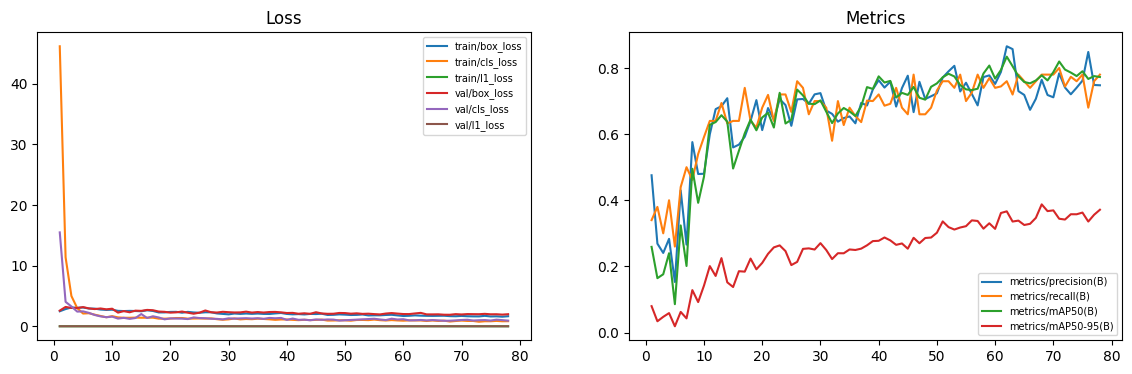

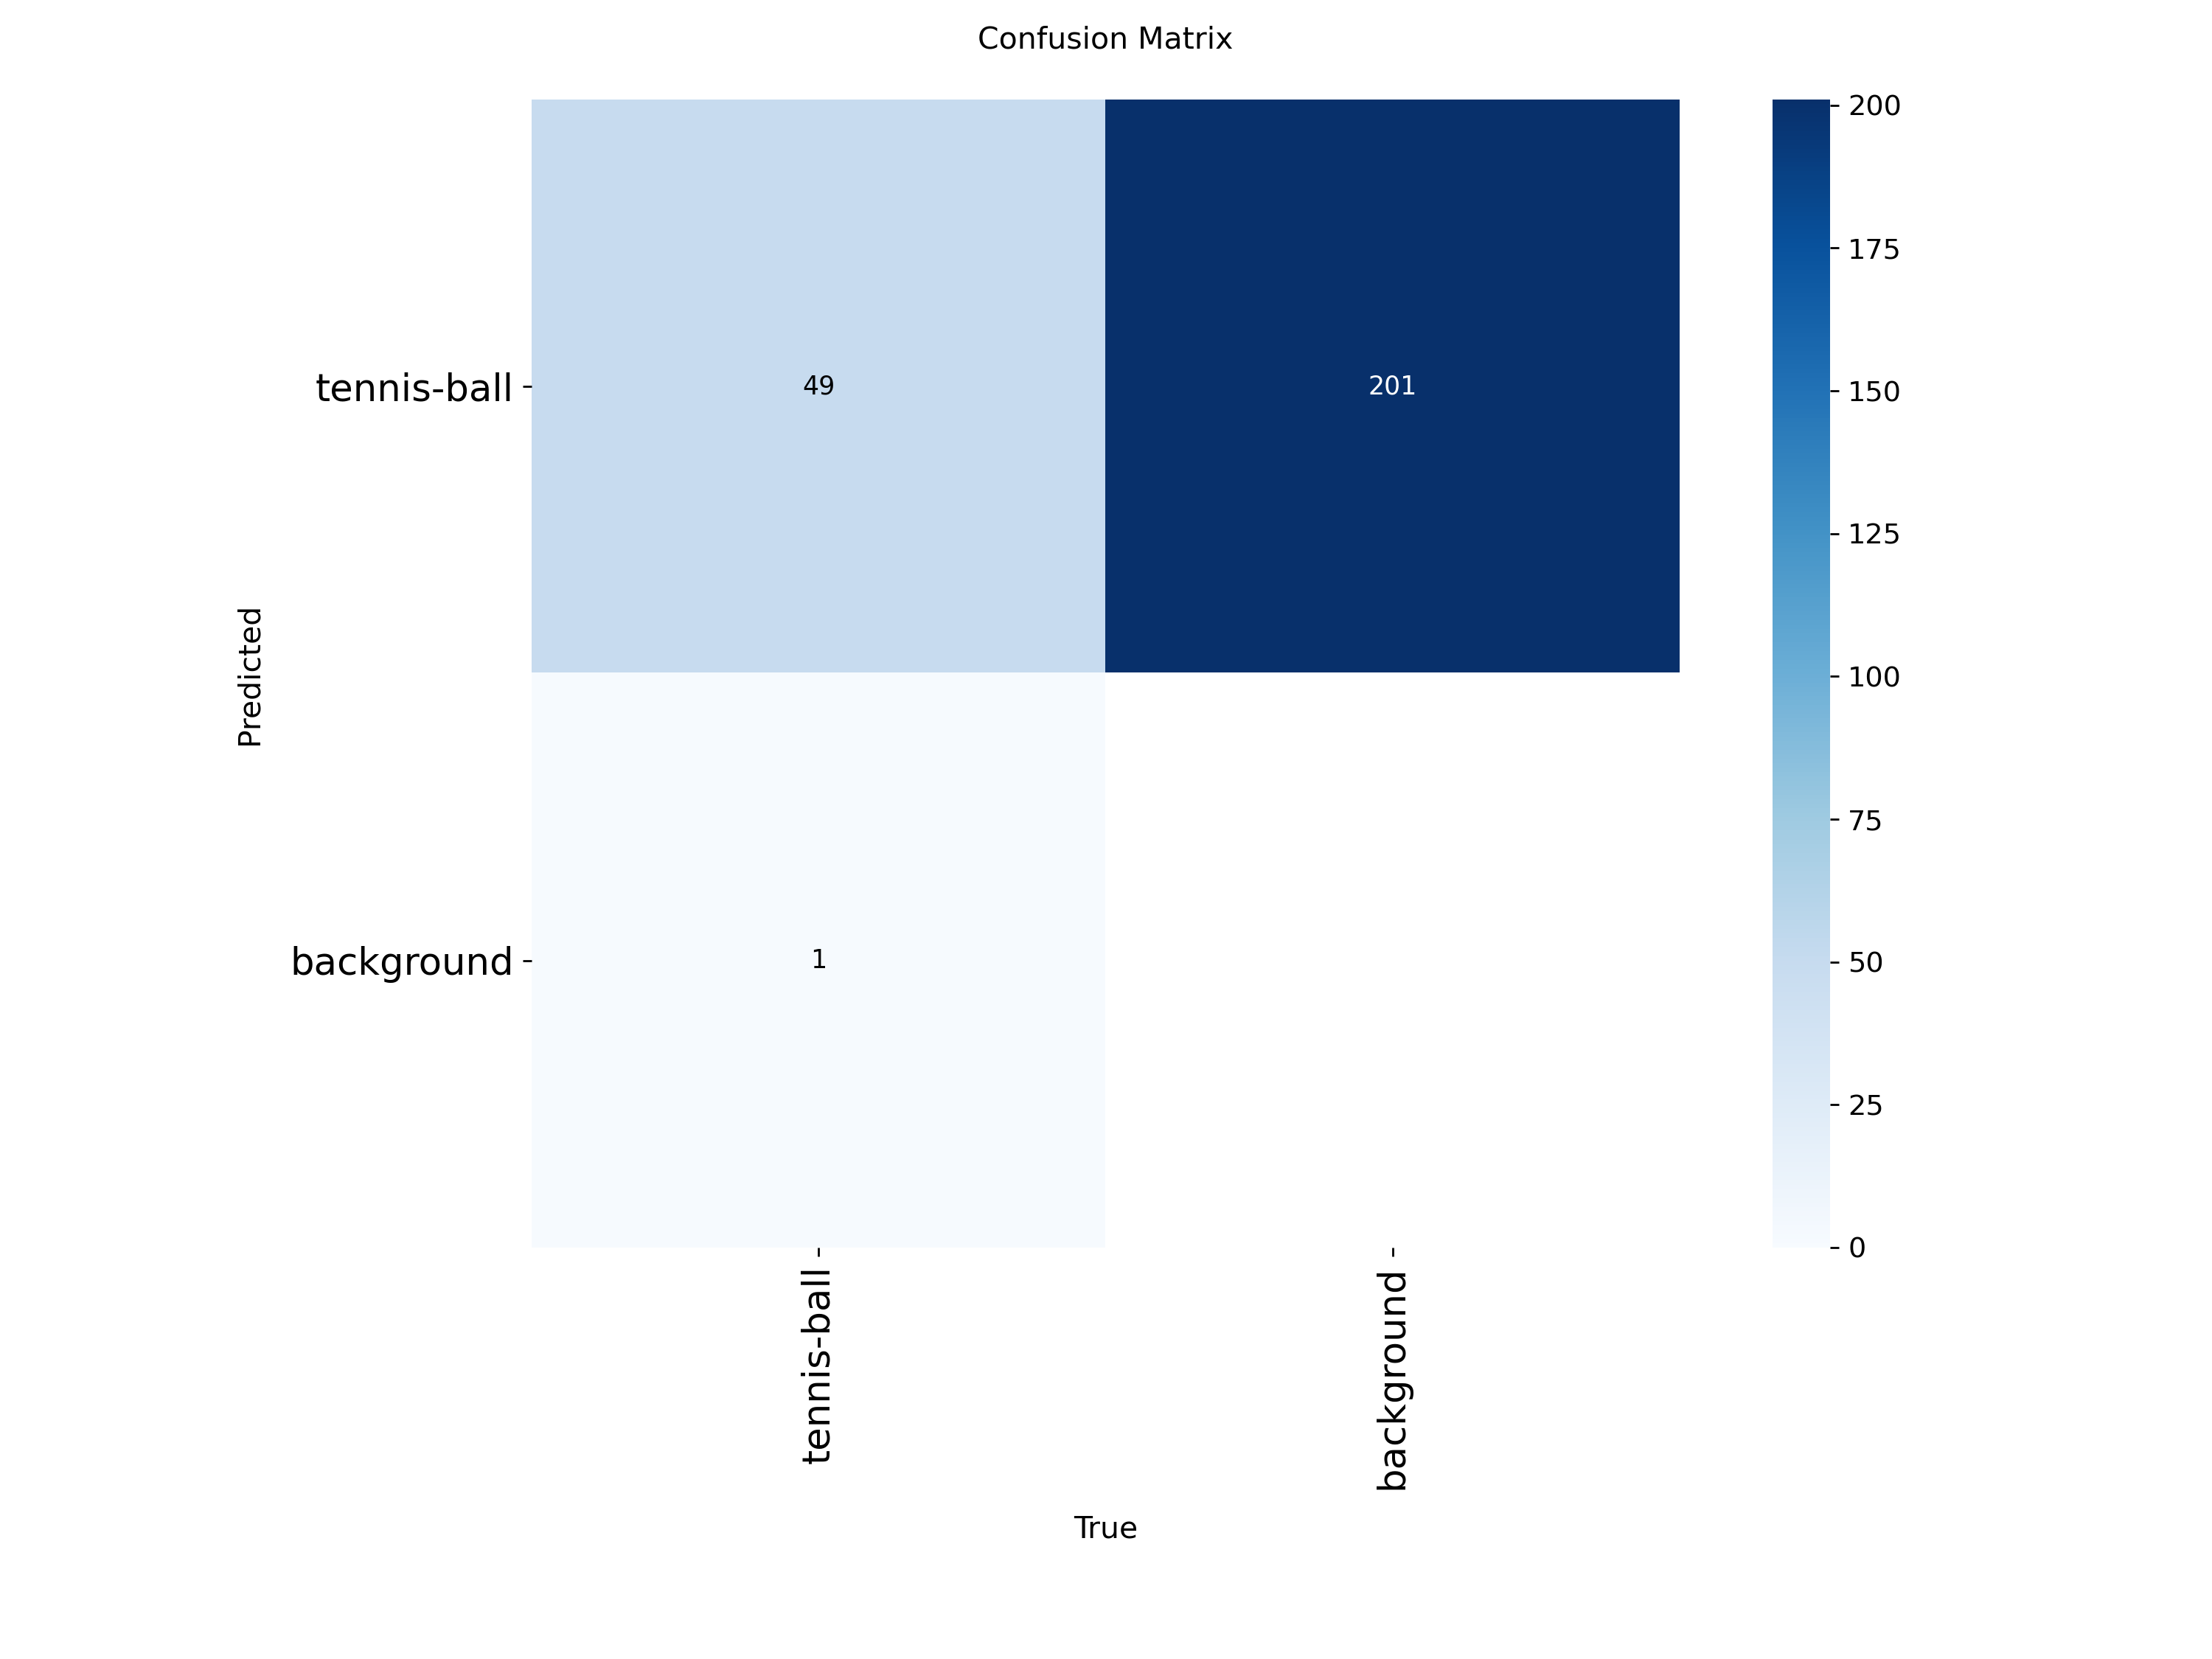

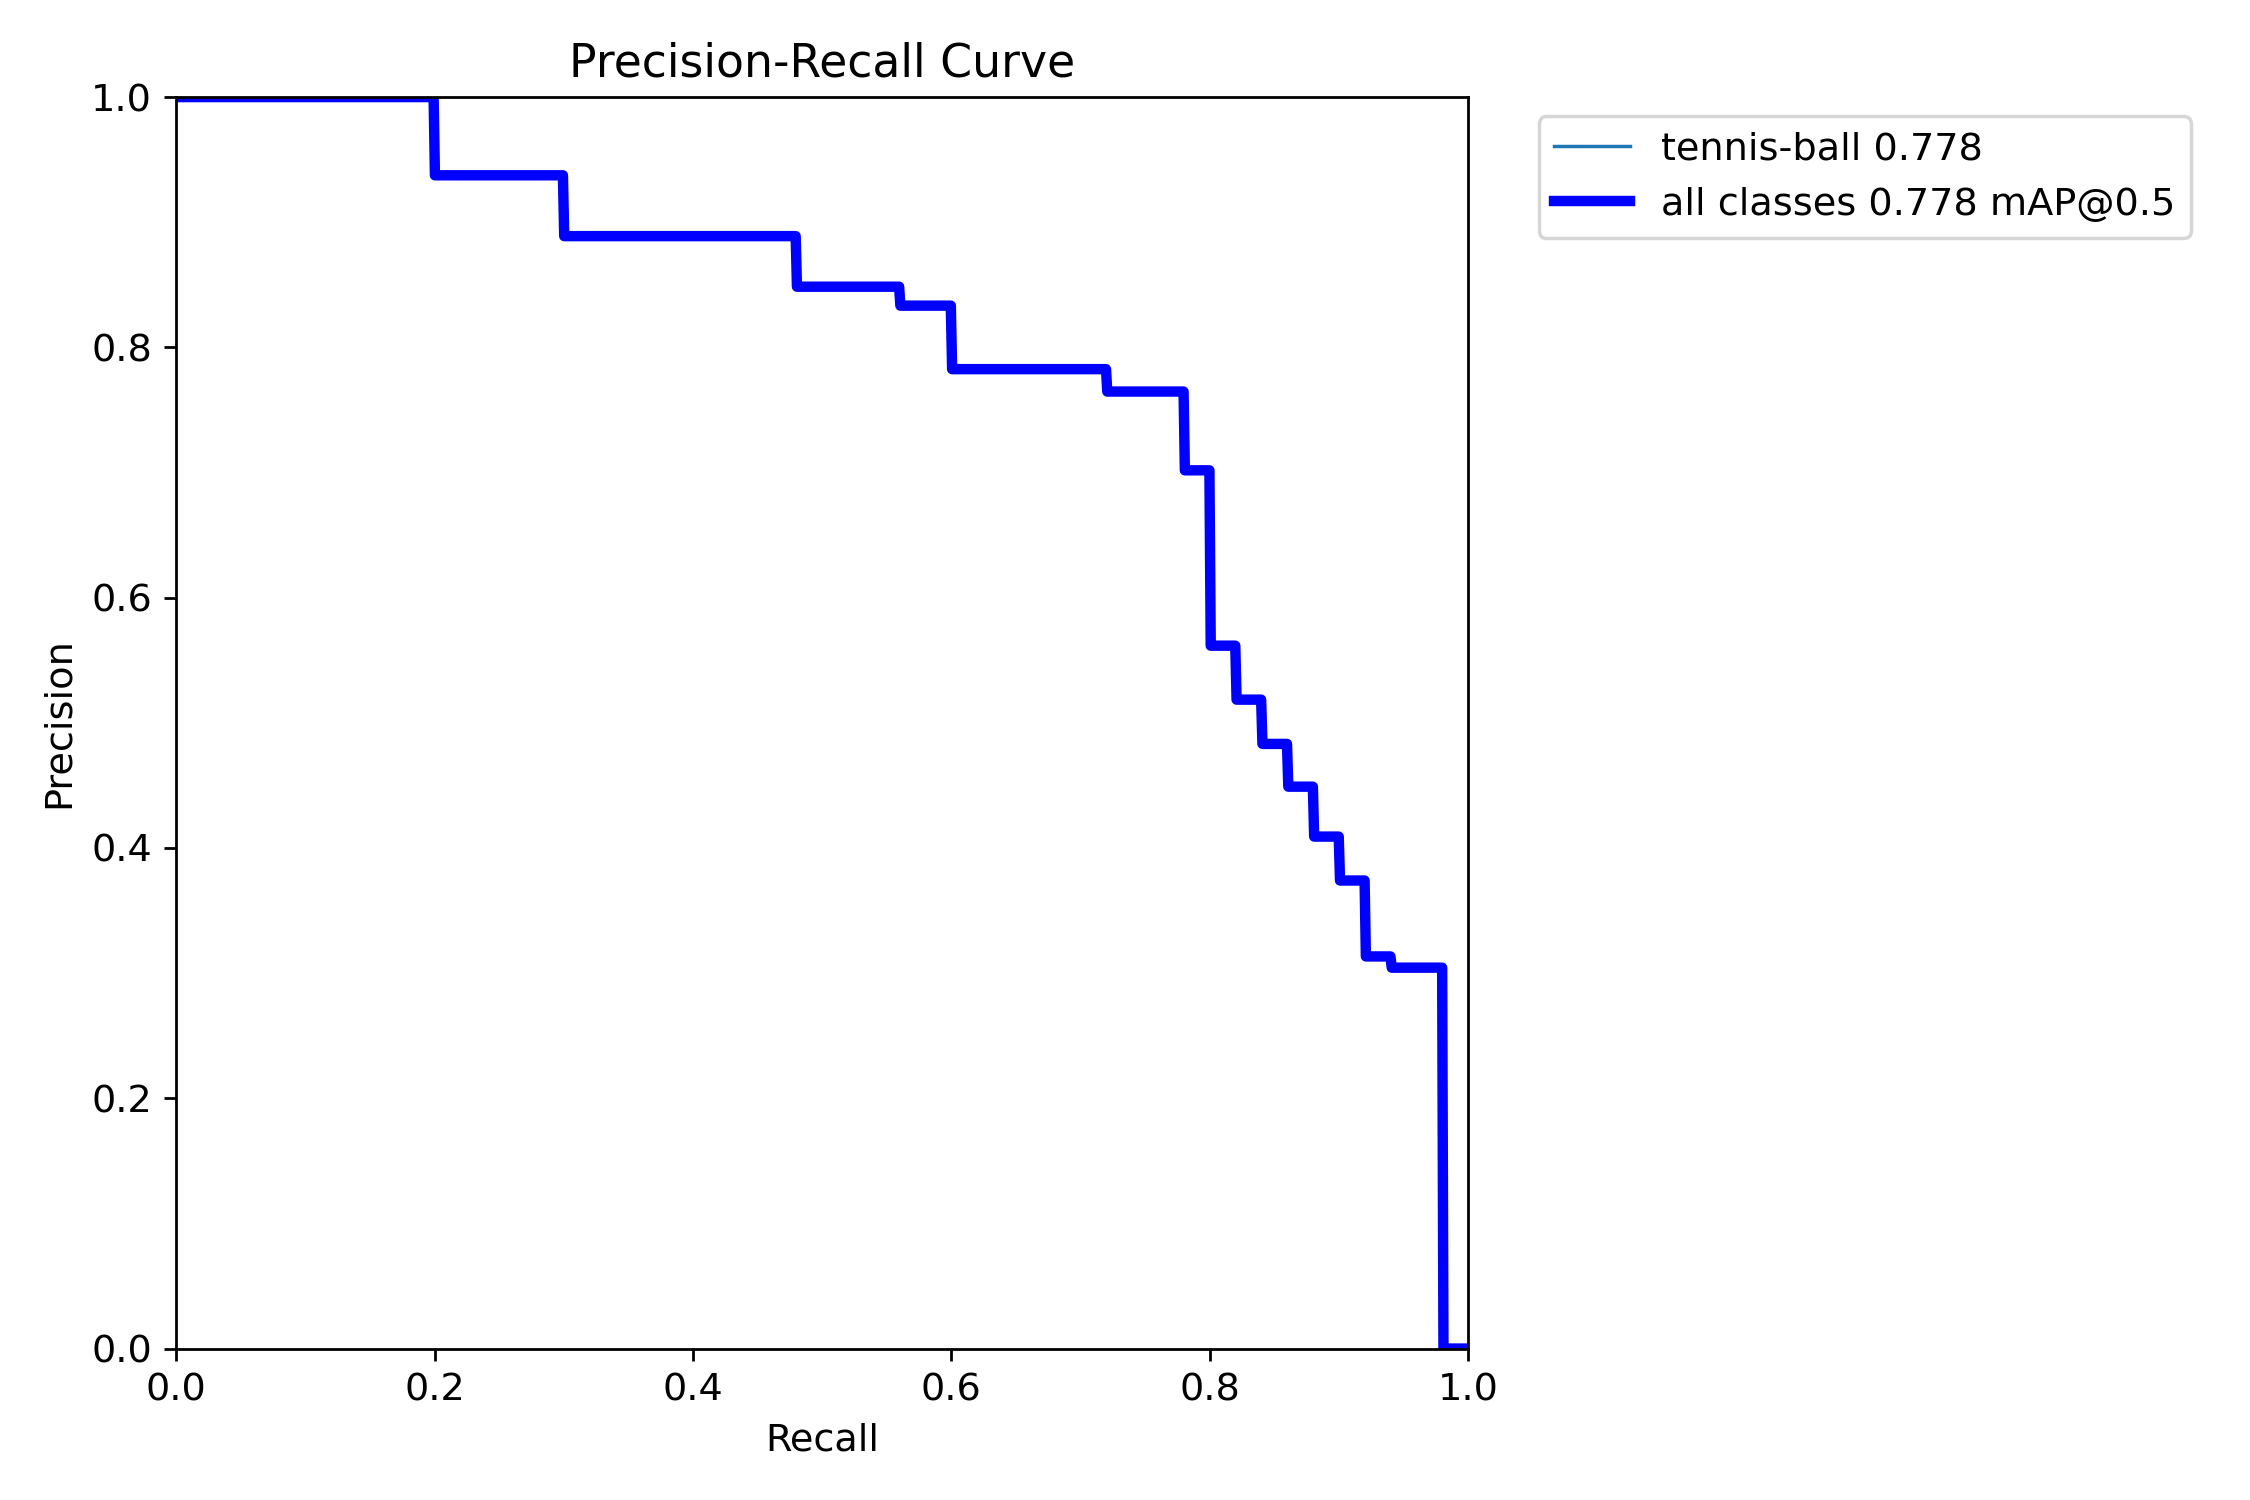

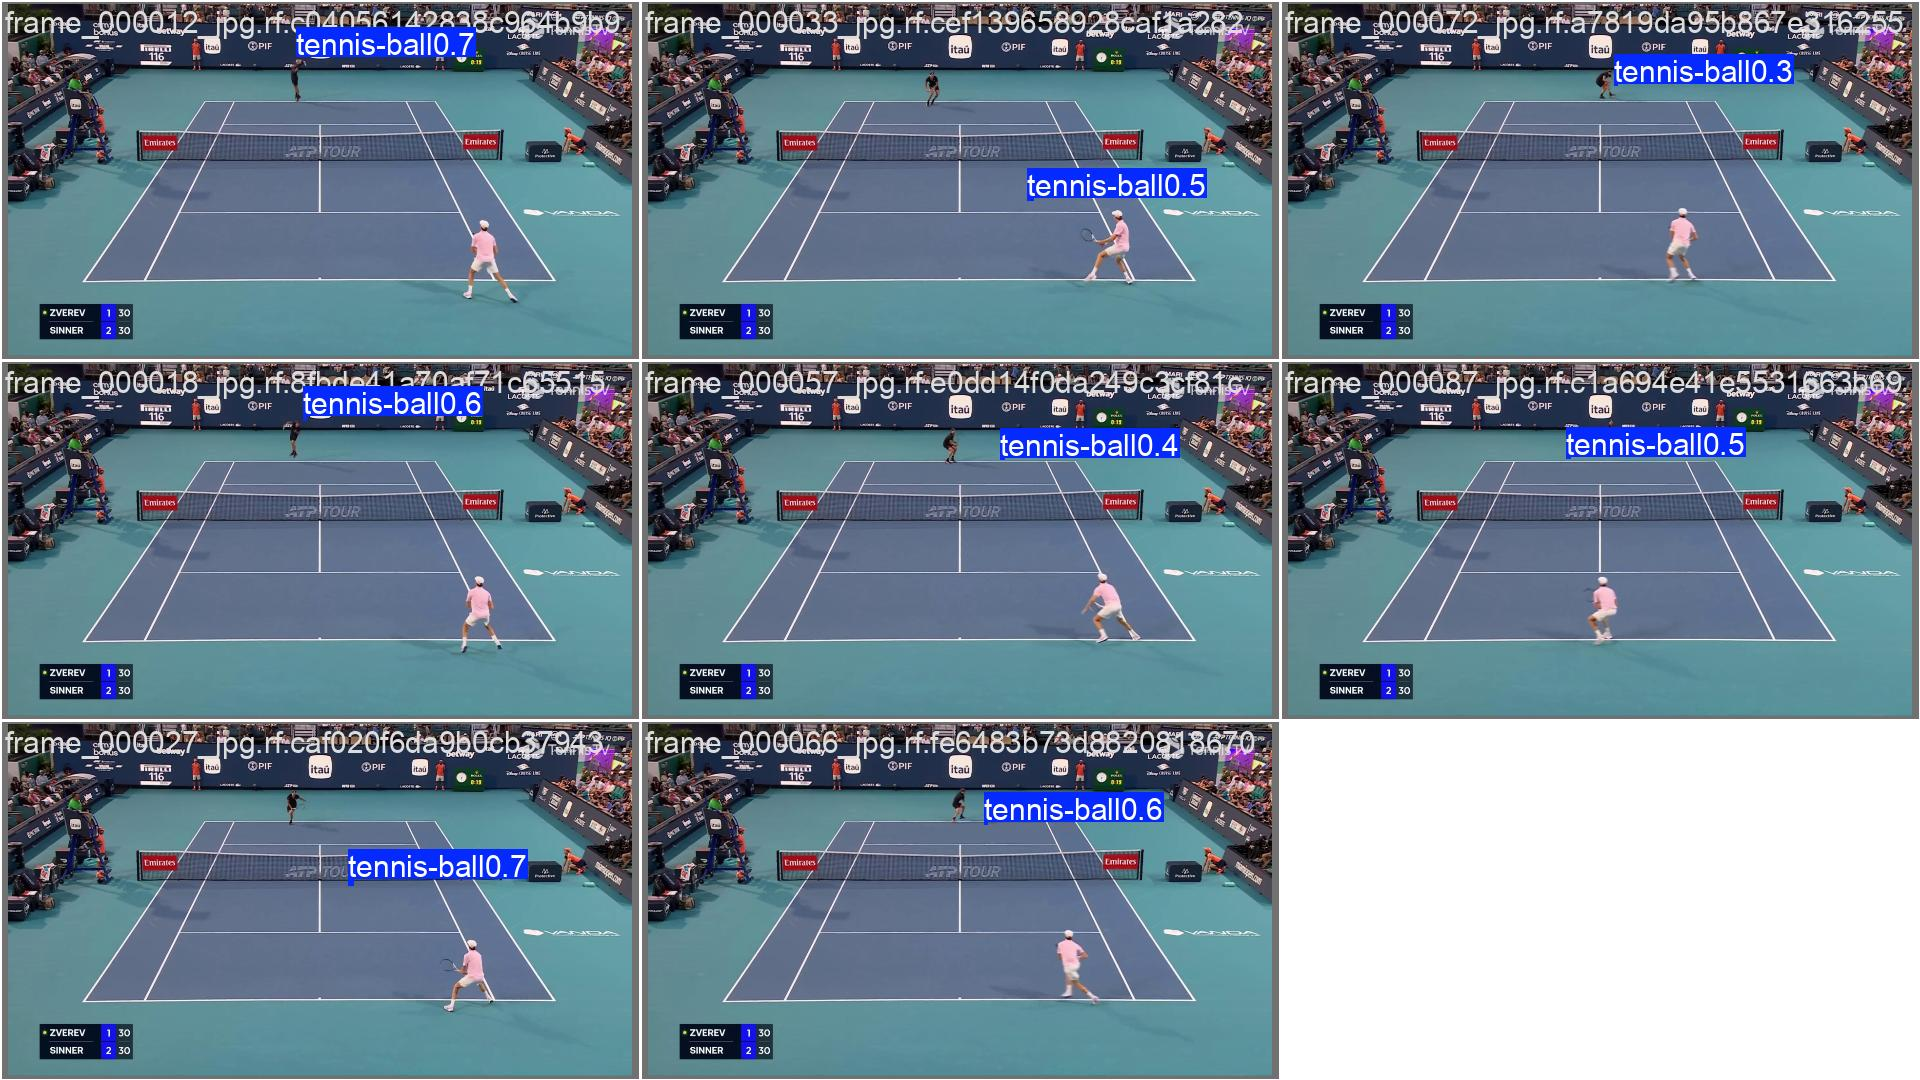

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

run_dir = Path('/content/runs/detect/runs_tennis/ball_train')
# Nếu Ultralytics tự thêm hậu tố (vd. ball_train2) thì lấy thư mục mới nhất
if not (run_dir / "weights" / "best.pt").exists():
    run_dir = max(Path(PROJECT).glob(f"{RUN_NAME}*"), key=lambda p: p.stat().st_mtime)
print("run_dir:", run_dir)

df = pd.read_csv(run_dir / "results.csv")
df.columns = [c.strip() for c in df.columns]

loss_cols = [c for c in df.columns if "loss" in c]
metric_cols = [c for c in df.columns if c.startswith("metrics/")]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for c in loss_cols:
    ax[0].plot(df["epoch"], df[c], label=c)
ax[0].set_title("Loss")
ax[0].legend(fontsize=7)
for c in metric_cols:
    ax[1].plot(df["epoch"], df[c], label=c)
ax[1].set_title("Metrics")
ax[1].legend(fontsize=7)
plt.show()

from IPython.display import Image, display
for name in ("confusion_matrix.png", "BoxPR_curve.png", "val_batch0_pred.jpg"):
    f = run_dir / name
    if f.exists():
        display(Image(filename=str(f), width=700))

## 6. Đánh giá model tốt nhất

In [16]:
best = YOLO(str(run_dir / "weights" / "best.pt"))

eval_split = "test" if "test" in cfg else "val"
m = best.val(data=str(DATA_YAML), split=eval_split, imgsz=IMGSZ, conf=0.001)

print(f"\nSplit: {eval_split}")
print(f"Precision : {m.box.mp:.3f}")
print(f"Recall    : {m.box.mr:.3f}")
print(f"mAP@0.5   : {m.box.map50:.3f}")
print(f"mAP@0.5:.95: {m.box.map:.3f}")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,223 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4149.3±1203.3 MB/s, size: 177.1 KB)
val: Scanning /content/tennis-ball-1/valid/labels.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 14.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4s/it 5.6s
                   all         50         50      0.781       0.78      0.793      0.398
Speed: 17.7ms preprocess, 64.7ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/runs/detect/val-2

Split: val
Precision : 0.781
Recall    : 0.780
mAP@0.5   : 0.793
mAP@0.5:.95: 0.398


## 7. Dự đoán thử

Với bóng nhỏ, nên dùng `conf` thấp (0.2–0.3) rồi lọc lại bằng tracking/logic quỹ đạo thay vì đặt ngưỡng quá cao.

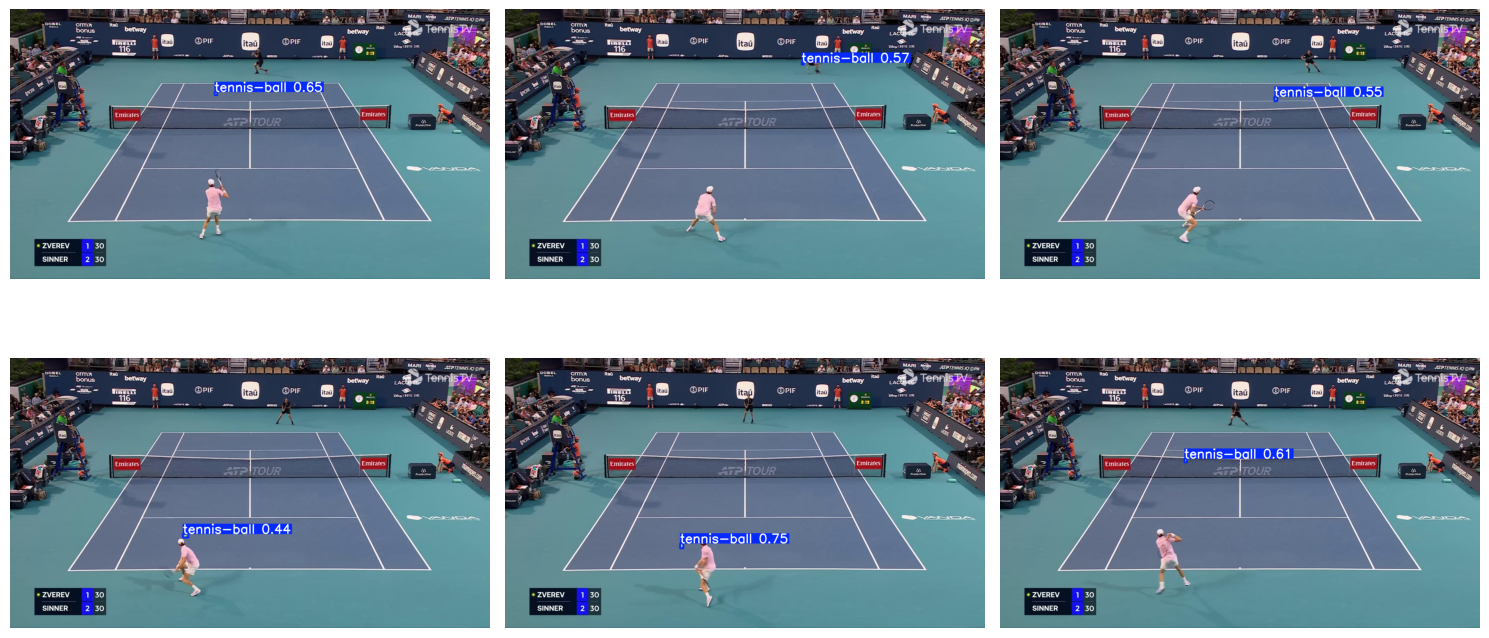

In [12]:
eval_imgs = list_images("val")
sample = random.sample(eval_imgs, min(6, len(eval_imgs)))

preds = best.predict([str(p) for p in sample], imgsz=IMGSZ, conf=0.25, verbose=False)

plt.figure(figsize=(15, 8))
for i, r in enumerate(preds):
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    plt.axis("off")
plt.tight_layout()
plt.show()

In [13]:
# Dự đoán trên video (đổi đường dẫn video của bạn)
VIDEO = "/content/tennis_clip.mp4"

if Path(VIDEO).exists():
    best.predict(VIDEO, imgsz=IMGSZ, conf=0.2, save=True, project=PROJECT, name="video_pred", exist_ok=True)
    print("Video kết quả nằm trong:", Path(PROJECT) / "video_pred")

    # Tracking giữ ID/quỹ đạo bóng qua các frame:
    # best.track(VIDEO, imgsz=IMGSZ, conf=0.2, persist=True, save=True, tracker="bytetrack.yaml")
else:
    print("Chưa có video – bỏ qua ô này.")

Chưa có video – bỏ qua ô này.


## 8. Export & tải về

In [14]:
onnx_path = best.export(format="onnx", imgsz=IMGSZ)   # thêm half=True nếu deploy GPU FP16
print("ONNX:", onnx_path)

try:
    from google.colab import files
    files.download(str(run_dir / "weights" / "best.pt"))
except Exception:
    print("best.pt nằm ở:", run_dir / "weights" / "best.pt")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26m summary (fused): 130 layers, 20,350,223 parameters, 0 gradients, 275.3 GFLOPs

PyTorch: starting from '/content/runs/detect/runs_tennis/ball_train/weights/best.pt' with input shape (1, 3, 1280, 1280) BCHW and output shape(s) (1, 5, 33600) (42.0 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 534ms
Prepared 4 packages in 875ms
Installed 4 packages in 45ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Gợi ý cải thiện nếu kết quả chưa tốt

- **Recall thấp / bóng xa bị bỏ sót** → tăng `imgsz` (1280 → 1536), hoặc chạy suy luận dạng chia ô bằng [SAHI](https://github.com/obss/sahi).
- **Nhiều false positive** (logo, đèn, đốm trắng) → thêm ảnh nền (không có bóng) vào train, khoảng 5–10% dataset.
- **Overfit** (train loss giảm nhưng val mAP đứng) → thêm dữ liệu đa dạng sân/góc quay, tăng `weight_decay`, hoặc dùng model nhỏ hơn.
- **Bóng bị mờ do chuyển động** → đảm bảo dataset có nhiều ảnh motion blur; có thể thêm augment blur qua Albumentations.
- **Loss dao động mạnh** → giảm `lr0` (ví dụ 0.001) và tăng `batch`.
- **Tự dò hyperparameter**: `best.tune(data=..., epochs=30, iterations=100, imgsz=IMGSZ)` (tốn thời gian, chỉ nên làm sau khi baseline đã ổn).
- **Nhãn**: kiểm tra box ôm sát bóng, không bỏ sót bóng nào – với vật thể nhỏ, lệch vài pixel đã ảnh hưởng lớn tới mAP.